# 02 · Train: baseline vs fine-tuned ResNet-18

In [1]:
import os, sys
REPO_URL = "https://github.com/YUPWE/car-size.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/car-size"
    if not os.path.exists(ROOT):
        !git clone {REPO_URL} {ROOT}
    os.chdir(ROOT)
    !git pull -q
    !pip install -q imagehash==4.3.2
    os.environ["CARS_DATA_DIR"] = "/content/cars_data"
else:
    ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    os.chdir(ROOT)
sys.path.insert(0, ROOT)
os.makedirs("results", exist_ok=True)
os.makedirs("weights", exist_ok=True)
QUICK = os.environ.get("QUICK", "0") == "1"
print("Working in", os.getcwd(), "| QUICK =", QUICK)

Mounted at /content/drive
Working in /content/drive/MyDrive/car-size | QUICK = False


In [2]:
import json, numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src import data
from src.data import CLASSES, CarDataset, get_transforms
from src.model import build_resnet18, train, set_seed, get_device

data.download()
device = get_device()
import torchvision, transformers, sklearn, pandas, matplotlib, PIL
print("device:", device)
for m in [torch, torchvision, transformers, sklearn, pandas, matplotlib, PIL]: print(f"  {m.__name__}=={m.__version__}")
set_seed(42)

train_df, val_df = data.load_split("train"), data.load_split("val")
if QUICK:
    train_df, val_df = train_df.sample(64, random_state=0), val_df.sample(32, random_state=0)
train_loader = DataLoader(CarDataset(train_df, get_transforms(True)), batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(CarDataset(val_df, get_transforms(False)), batch_size=128, num_workers=2)
print(len(train_df), "train /", len(val_df), "val images")

counts = train_df.label.value_counts().reindex(CLASSES).values
class_weights = counts.sum() / (len(CLASSES) * counts)
print("class weights:", dict(zip(CLASSES, class_weights.round(2))))

Unzipping cached images ...
device: cuda
  torch==2.14.1+cu130
  torchvision==0.29.1+cu130
  transformers==5.22.1
  sklearn==1.6.1
  pandas==2.2.3
  matplotlib==3.10.0
  PIL==11.3.0
11611 train / 2304 val images
class weights: {'small': np.float64(0.78), 'big': np.float64(1.39)}


In [3]:
EPOCHS = 1 if QUICK else 8

set_seed(42)
baseline = build_resnet18(freeze_backbone=True)
baseline, hist_base = train(baseline, train_loader, val_loader, epochs=EPOCHS, lr=1e-3,
                            device=device, class_weights=class_weights)
torch.save(baseline.state_dict(), "weights/resnet18_frozen.pt")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 127MB/s]


epoch  1/8 | train loss 0.376 acc 0.836 | val loss 0.348 acc 0.839 F1 0.829 | 94s
epoch  2/8 | train loss 0.278 acc 0.887 | val loss 0.286 acc 0.875 F1 0.861 | 75s
epoch  3/8 | train loss 0.261 acc 0.891 | val loss 0.289 acc 0.872 F1 0.862 | 69s
epoch  4/8 | train loss 0.252 acc 0.896 | val loss 0.268 acc 0.893 F1 0.880 | 70s
epoch  5/8 | train loss 0.247 acc 0.897 | val loss 0.270 acc 0.888 F1 0.877 | 70s
epoch  6/8 | train loss 0.239 acc 0.903 | val loss 0.292 acc 0.869 F1 0.860 | 71s
epoch  7/8 | train loss 0.245 acc 0.898 | val loss 0.275 acc 0.882 F1 0.871 | 76s
epoch  8/8 | train loss 0.235 acc 0.904 | val loss 0.267 acc 0.890 F1 0.877 | 74s
Best validation macro-F1: 0.880


In [4]:
set_seed(42)
finetuned = build_resnet18(freeze_backbone=False)
finetuned, hist_ft = train(finetuned, train_loader, val_loader, epochs=EPOCHS, lr=2e-4,
                           device=device, class_weights=class_weights)
torch.save(finetuned.state_dict(), "weights/resnet18_finetuned.pt")

epoch  1/8 | train loss 0.171 acc 0.930 | val loss 0.221 acc 0.909 F1 0.902 | 77s
epoch  2/8 | train loss 0.066 acc 0.976 | val loss 0.199 acc 0.941 F1 0.931 | 75s
epoch  3/8 | train loss 0.044 acc 0.984 | val loss 0.142 acc 0.950 F1 0.945 | 77s
epoch  4/8 | train loss 0.031 acc 0.989 | val loss 0.148 acc 0.945 F1 0.938 | 78s
epoch  5/8 | train loss 0.019 acc 0.993 | val loss 0.143 acc 0.960 F1 0.955 | 78s
epoch  6/8 | train loss 0.015 acc 0.995 | val loss 0.151 acc 0.956 F1 0.950 | 78s
epoch  7/8 | train loss 0.008 acc 0.998 | val loss 0.145 acc 0.961 F1 0.955 | 78s
epoch  8/8 | train loss 0.005 acc 0.998 | val loss 0.141 acc 0.961 F1 0.955 | 82s
Best validation macro-F1: 0.955


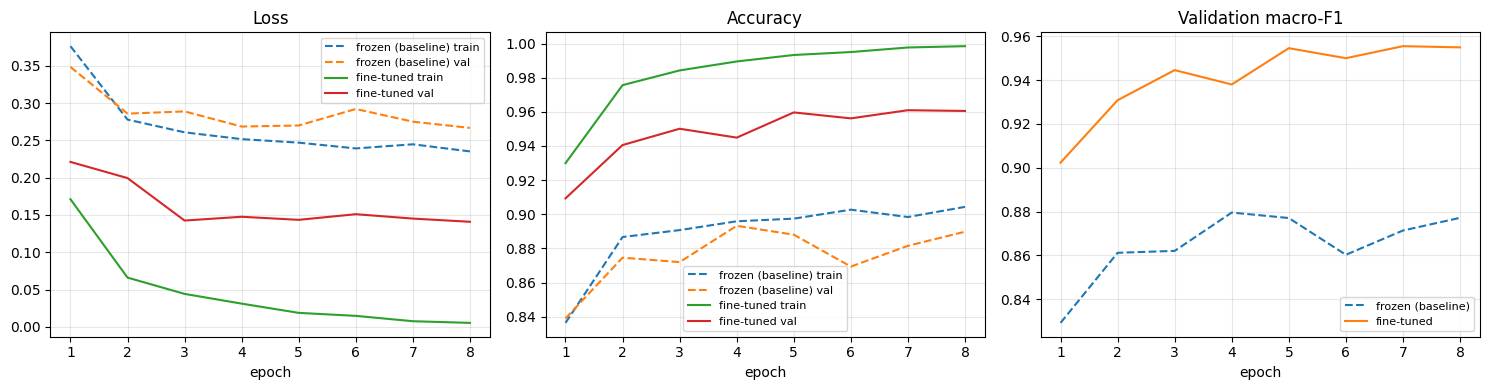

baseline (frozen)  best val macro-F1 0.880 | best val acc 0.893
fine-tuned         best val macro-F1 0.955 | best val acc 0.961


In [5]:
json.dump({"baseline_frozen": hist_base, "finetuned": hist_ft}, open("results/history.json", "w"), indent=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, h, style in [("frozen (baseline)", hist_base, "--"), ("fine-tuned", hist_ft, "-")]:
    ep = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], style, label=f"{name} train"); axes[0].plot(ep, h["val_loss"], style, label=f"{name} val")
    axes[1].plot(ep, h["train_acc"], style, label=f"{name} train"); axes[1].plot(ep, h["val_acc"], style, label=f"{name} val")
    axes[2].plot(ep, h["val_f1"], style, label=name)
for ax, t in zip(axes, ["Loss", "Accuracy", "Validation macro-F1"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/curves.png", dpi=120); plt.show()

for name, h in [("baseline (frozen)", hist_base), ("fine-tuned", hist_ft)]:
    print(f"{name:18s} best val macro-F1 {max(h['val_f1']):.3f} | best val acc {max(h['val_acc']):.3f}")

### Reading the curves